In [235]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.decomposition import PCA

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [236]:
df = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# Pembersihan Data

In [237]:
rows, cols = df.shape
print("Kolom:", cols)
print("Baris:", rows)
print(df.info())
print(df.describe())
nn:int=0
hv_na = []
for i in df.columns:
    temp=df[i].isna().sum()
    print(i," ",temp)
    if temp:
        _t = round(temp/rows,2)
        hv_na.append((_t,i))
    nn+=temp
print("All:",nn)

Kolom: 81
Baris: 1460
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null  

Terdapat 81 Kolom dengan 1460 baris data. Terdapat 7829 cell NaN. fitur `Alley`,`PoolQC`, `Fence` dan `MiscFeature` mayoritas datanya adalah NaN

In [238]:
hv_na

[(np.float64(0.18), 'LotFrontage'),
 (np.float64(0.94), 'Alley'),
 (np.float64(0.6), 'MasVnrType'),
 (np.float64(0.01), 'MasVnrArea'),
 (np.float64(0.03), 'BsmtQual'),
 (np.float64(0.03), 'BsmtCond'),
 (np.float64(0.03), 'BsmtExposure'),
 (np.float64(0.03), 'BsmtFinType1'),
 (np.float64(0.03), 'BsmtFinType2'),
 (np.float64(0.0), 'Electrical'),
 (np.float64(0.47), 'FireplaceQu'),
 (np.float64(0.06), 'GarageType'),
 (np.float64(0.06), 'GarageYrBlt'),
 (np.float64(0.06), 'GarageFinish'),
 (np.float64(0.06), 'GarageQual'),
 (np.float64(0.06), 'GarageCond'),
 (np.float64(1.0), 'PoolQC'),
 (np.float64(0.81), 'Fence'),
 (np.float64(0.96), 'MiscFeature')]

In [239]:
for i in hv_na:
    if i[0]:
        print(df[i[1]].value_counts(dropna=False))
        print(i[0]*100,"%\n\n")


LotFrontage
NaN      259
60.0     143
70.0      70
80.0      69
50.0      57
        ... 
182.0      1
160.0      1
152.0      1
153.0      1
46.0       1
Name: count, Length: 111, dtype: int64
18.0 %


Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64
94.0 %


MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64
60.0 %


MasVnrArea
0.0      861
108.0      8
NaN        8
72.0       8
180.0      8
        ... 
426.0      1
96.0       1
438.0      1
194.0      1
119.0      1
Name: count, Length: 328, dtype: int64
1.0 %


BsmtQual
TA     649
Gd     618
Ex     121
NaN     37
Fa      35
Name: count, dtype: int64
3.0 %


BsmtCond
TA     1311
Gd       65
Fa       45
NaN      37
Po        2
Name: count, dtype: int64
3.0 %


BsmtExposure
No     953
Av     221
Gd     134
Mn     114
NaN     38
Name: count, dtype: int64
3.0 %


BsmtFinType1
Unf    430
GLQ    418
ALQ    220
BLQ    148
Rec    133
LwQ     74
NaN     37
Name: count, dtyp

Mayoritas data dengan NaN adalah data kategorikal. Sesuai perintah, maka fitur dengan lebih dari 50% NaN harus di-drop.

In [240]:
cp = hv_na.copy()
below_50 = []
for i in cp:
    if i[0]>0.5:
        print(f"Dropping {i[1]}...")
        df = df.drop(columns=[i[1]],axis=1)
        hv_na.remove(i)
    else:
        below_50.append(i[1])
df.head()
print(hv_na)

Dropping Alley...
Dropping MasVnrType...
Dropping PoolQC...
Dropping Fence...
Dropping MiscFeature...
[(np.float64(0.18), 'LotFrontage'), (np.float64(0.01), 'MasVnrArea'), (np.float64(0.03), 'BsmtQual'), (np.float64(0.03), 'BsmtCond'), (np.float64(0.03), 'BsmtExposure'), (np.float64(0.03), 'BsmtFinType1'), (np.float64(0.03), 'BsmtFinType2'), (np.float64(0.0), 'Electrical'), (np.float64(0.47), 'FireplaceQu'), (np.float64(0.06), 'GarageType'), (np.float64(0.06), 'GarageYrBlt'), (np.float64(0.06), 'GarageFinish'), (np.float64(0.06), 'GarageQual'), (np.float64(0.06), 'GarageCond')]


In [241]:
num_cols_missing = (
    df[below_50].select_dtypes(include=[np.number]).columns.tolist()
)
cat_cols_missing = (
    df[below_50]
    .select_dtypes(include=['object', 'category'])
    .columns.tolist()
)
print(num_cols_missing,cat_cols_missing)

['LotFrontage', 'MasVnrArea', 'GarageYrBlt'] ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']


Fitur dengan NaN lebih dari $50%$ telah di-drop dan telah dilakukan pemisahan terhadap kolom NaN numerik dan Kategorikal. Sebelum melanjutkan, berikut informasi lanjut mengenai kolom-kolom tesebut:
### Numerik
* LotFrontage: Linear feet of street connected to property
* MasVnrArea: Masonry veneer area in square feet
* GarageYrBlt: Year garage was built
### Kategorikal
* BsmtQual: Height of the basement
* BsmtCond: General condition of the basement
* BsmtExposure: Walkout or garden level basement walls
* BsmtFinSF1: Type 1 finished square feet
* BsmtFinType2: Quality of second finished area (if present)
* Electrical: Electrical system
* FireplaceQu: Fireplace quality
* GarageType: Garage location
* GarageFinish: Interior finish of the garage
* GarageQual: Garage quality
* GarageCond: Garage condition

Dapat diketahui bahwa fitur/kolom kosong tersebut secara garis besar mendeskripsikan: Lot Frontage, Masonry veneer, Garage(garasi), Basement, Electrical, dan Fire Place.

Jika diperhatikan, fitur yang mendeksripsikan garasi dan basement memiliki jumlah missing value yang sama. Maka ada kemungkinan bahwa pada fitur fitur tersebut memang mendeksripsikan bahwa rumah tidak memiliki benda yang dideksripsikan fitur tersebut sendiri. Untuk membuktikannya maka perlu dilakukan cross check pada fitur yang mirip dan tidak memiliki missing/NaN. Contoh: fitur `Garagecars` atau `GarageArea` dapat merepresentasikan ada tidaknya garasi

In [242]:
has_garage = (
    (df['GarageCars'] > 0)
    | (df['GarageArea'] > 0)
    | df['GarageYrBlt'].notna()
    | df[
        ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
    ].notna().any(axis=1)
)

has_basement = (
    (df['TotalBsmtSF'] > 0)
    | (df['BsmtFinSF1'] > 0)
    | (df['BsmtFinSF2'] > 0)
    | (df['BsmtUnfSF'] > 0)
    | (df['BsmtFullBath'] > 0)
    | (df['BsmtHalfBath'] > 0)
    | df[
        [
            'BsmtQual',
            'BsmtCond',
            'BsmtExposure',
            'BsmtFinType1',
            'BsmtFinType2'
        ]
    ].notna().any(axis=1)
)

has_fireplace = df['Fireplaces'] > 0

has_masonry = df['MasVnrArea'].notna() & (df['MasVnrArea'] > 0)

garage_cat_cols = [
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond'
]

basement_cat_cols = [
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2'
]

for col in garage_cat_cols:
    df.loc[
        (~has_garage) & df[col].isna(),
        col
    ] = 'Kosong'

for col in basement_cat_cols:
    df.loc[
        (~has_basement) & df[col].isna(),
        col
    ] = 'Kosong'

df.loc[
    (~has_fireplace) & df['FireplaceQu'].isna(),
    'FireplaceQu'
] = 'Kosong'


df.loc[
    ~has_garage & df['GarageCars'].isna(),
    'GarageCars'
] = 0

df.loc[
    ~has_garage & df['GarageArea'].isna(),
    'GarageArea'
] = 0

df.loc[
    (~has_garage) & df['GarageYrBlt'].isna(),
    'GarageYrBlt'
] = df.loc[
    (~has_garage) & df['GarageYrBlt'].isna(),
    'YearBuilt'
]

for col in garage_cat_cols:
    if df[col].isna().any():
        df.loc[df[col].isna(), col] = df[col].mode()[0]

for col in basement_cat_cols:
    if df[col].isna().any():
        df.loc[df[col].isna(), col] = df[col].mode()[0]

if df['FireplaceQu'].isna().any():
    df.loc[
        df['FireplaceQu'].isna(),
        'FireplaceQu'
    ] = df['FireplaceQu'].mode()[0]

df['Electrical'] = df['Electrical'].fillna(
    df['Electrical'].mode()[0]
)

df['MasVnrArea'] = df['MasVnrArea'].fillna(
    df['MasVnrArea'].median()
)

df['LotFrontage'] = (
    df.groupby('Neighborhood')['LotFrontage']
      .transform(
          lambda x: x.fillna(x.median())
      )
)

df['LotFrontage'] = df['LotFrontage'].fillna(
    df['LotFrontage'].median()
)

garage_year_median = df.loc[
    has_garage,
    'GarageYrBlt'
].median()

df.loc[
    has_garage & df['GarageYrBlt'].isna(),
    'GarageYrBlt'
] = garage_year_median

print('Sisa total NaN:', df.isnull().sum().sum())
print('\nKolom yang masih memiliki NaN:')
print(df.isnull().sum()[df.isnull().sum() > 0])

Sisa total NaN: 0

Kolom yang masih memiliki NaN:
Series([], dtype: int64)


In [243]:
for i in df.columns:
    print(df[i].value_counts(dropna=False),end="\n\n")
    

Id
1460    1
1       1
2       1
3       1
1444    1
       ..
9       1
8       1
7       1
6       1
5       1
Name: count, Length: 1460, dtype: int64

MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64

MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

LotFrontage
60.0     152
80.0     112
70.0      94
65.0      74
73.0      70
        ... 
138.0      1
152.0      1
88.5       1
153.0      1
46.0       1
Name: count, Length: 115, dtype: int64

LotArea
7200     25
9600     24
6000     17
10800    14
8400     14
         ..
10652     1
12968     1
11924     1
14260     1
9550      1
Name: count, Length: 1073, dtype: int64

Street
Pave    1454
Grvl       6
Name: count, dtype: int64

LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64

LandContour

Pada frequensi memang ada "kosong", tapi itu adalah hasil modifikasi yang merepresentasikan bahwa suatu fitur itu tidak ada pada rumah x. Hal ini dibuktikan dengan pengecekan `print(df.isna().sum().sum())` yang menghasilkan $0$, menandakan bahwa hal tersebut memang hasil modifikasi

# Deteksi dan Penanganan Outlier

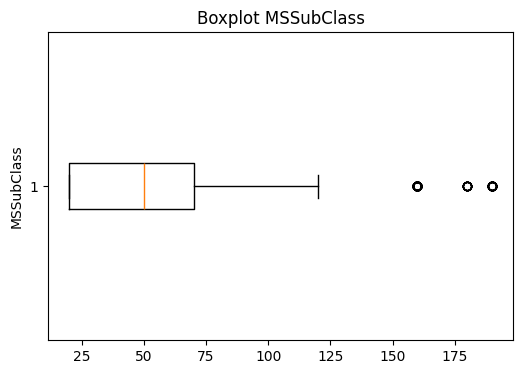

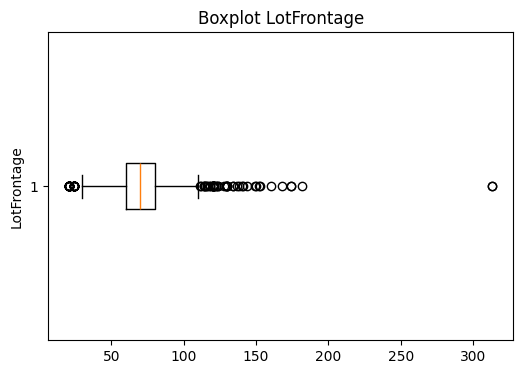

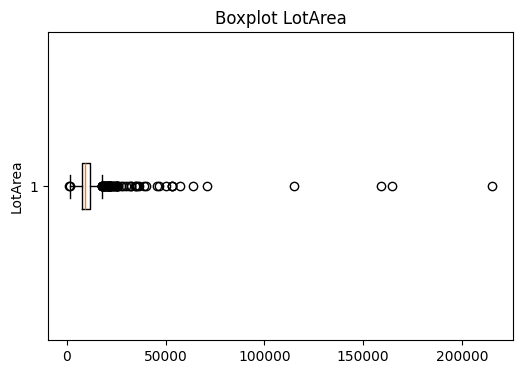

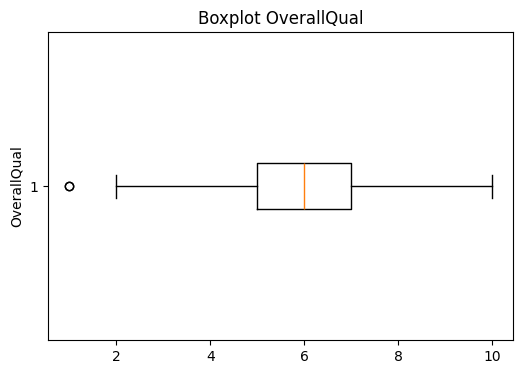

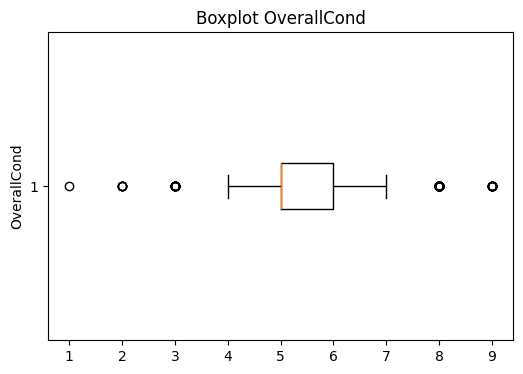

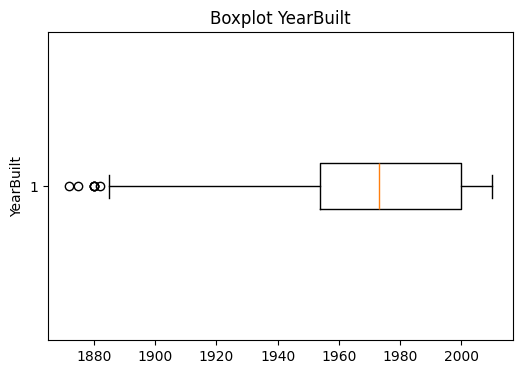

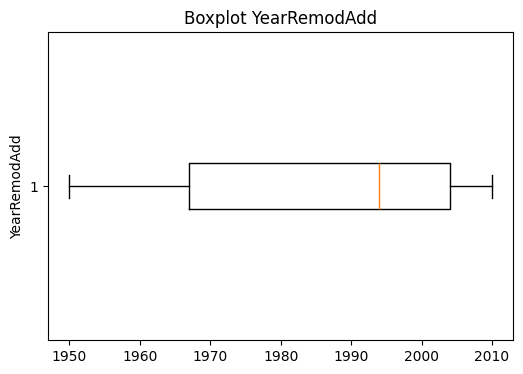

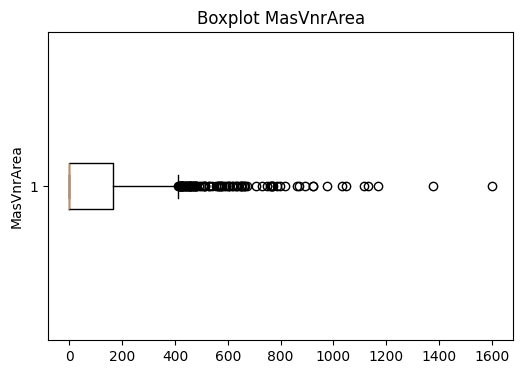

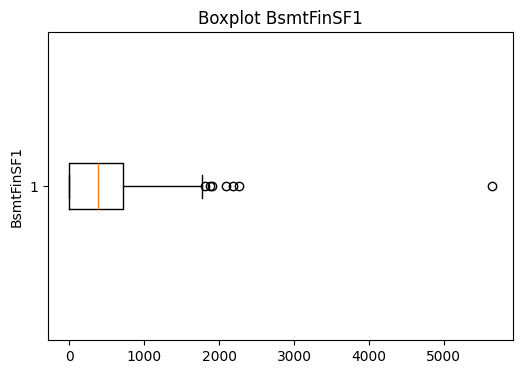

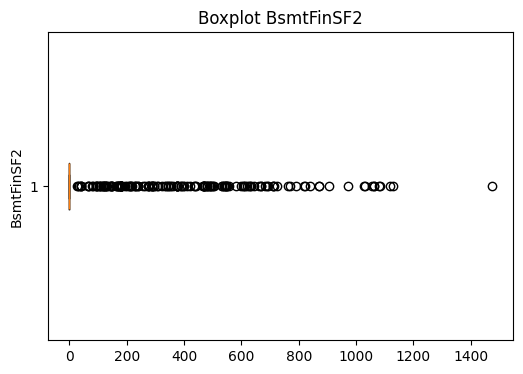

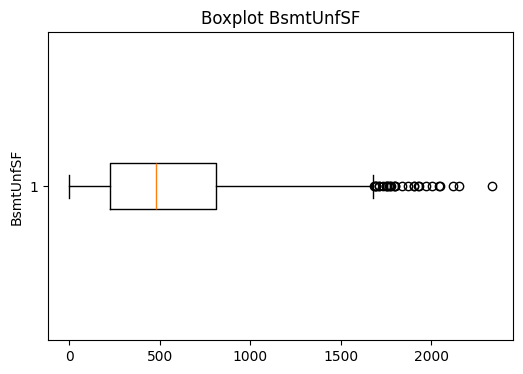

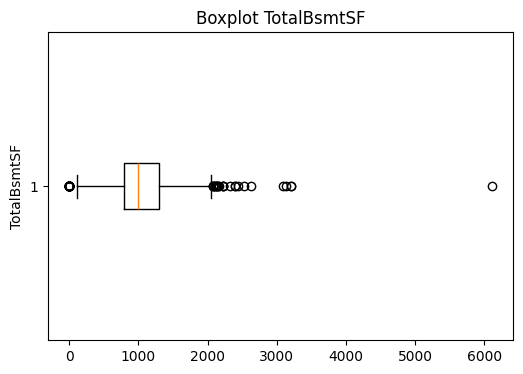

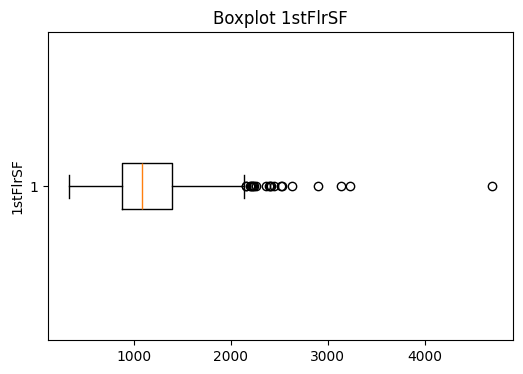

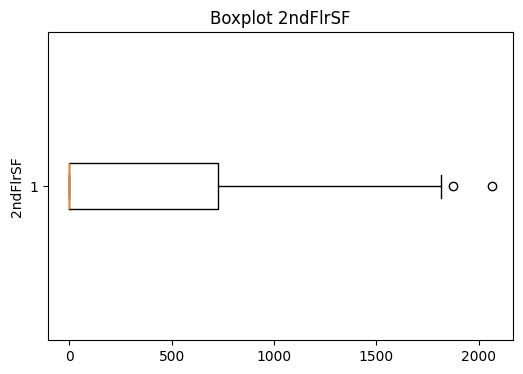

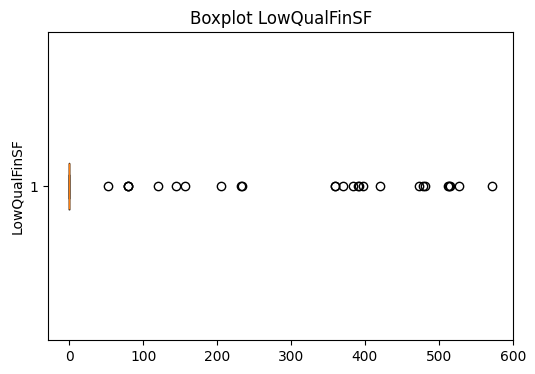

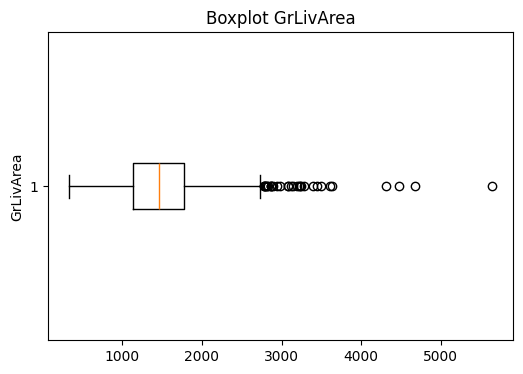

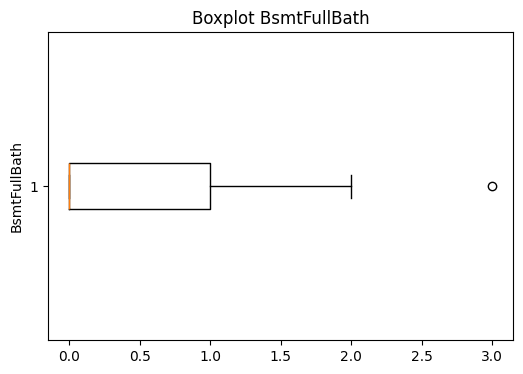

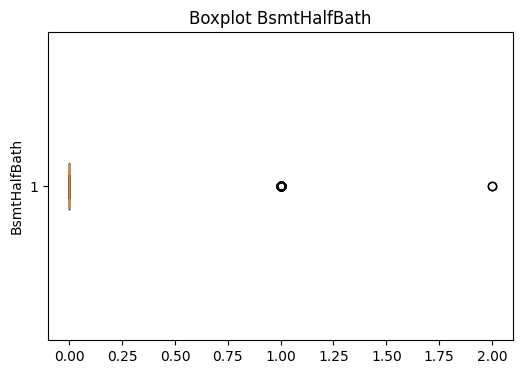

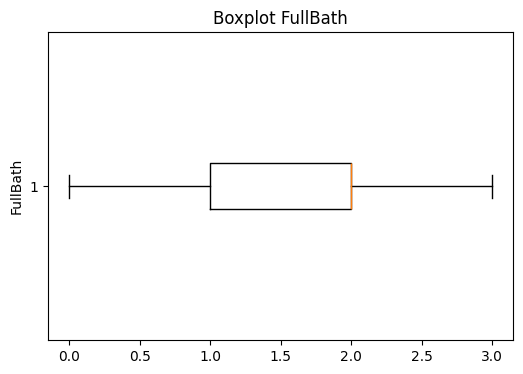

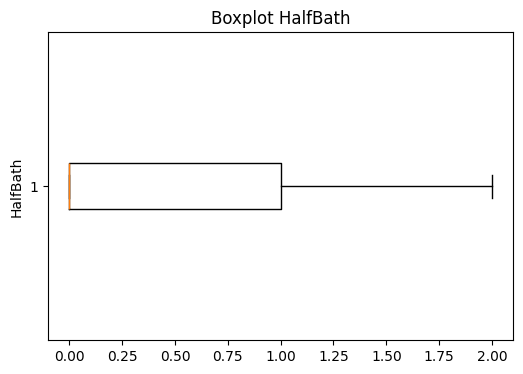

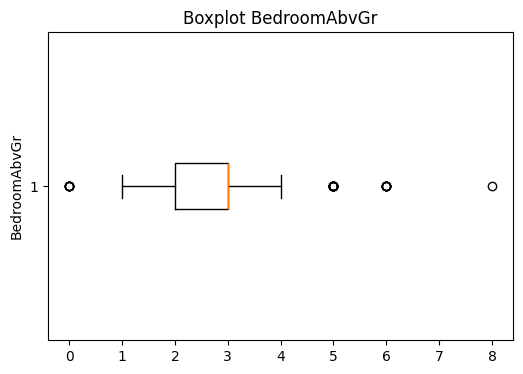

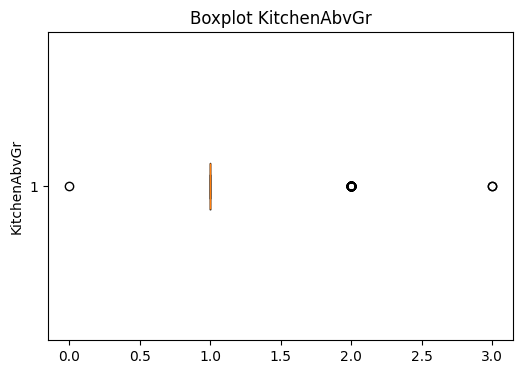

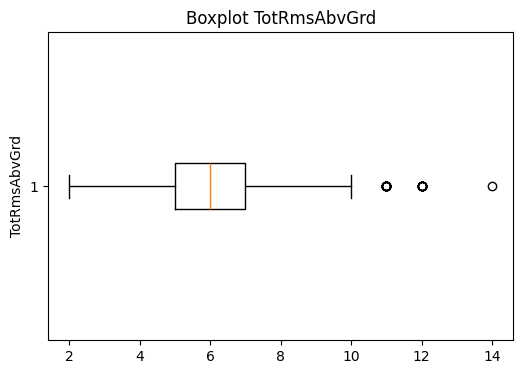

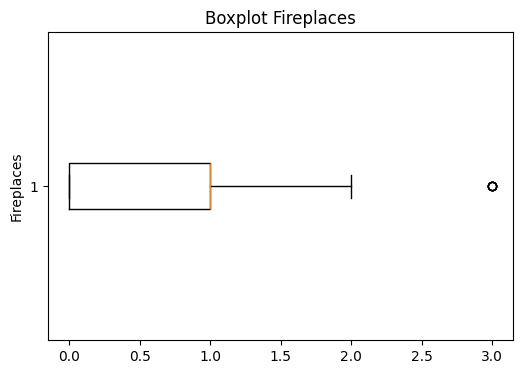

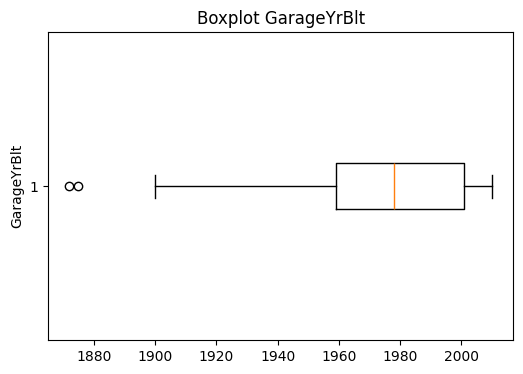

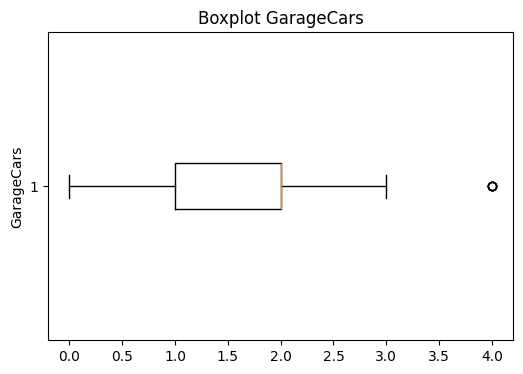

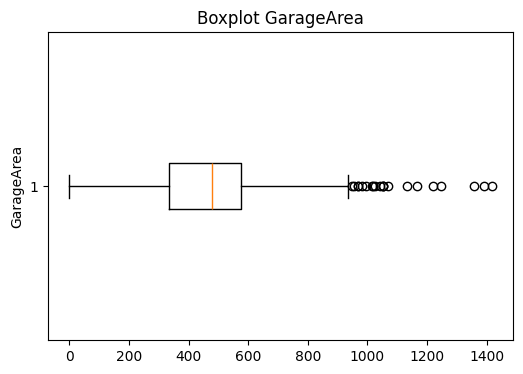

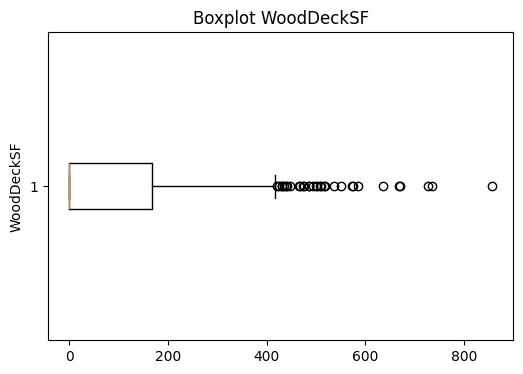

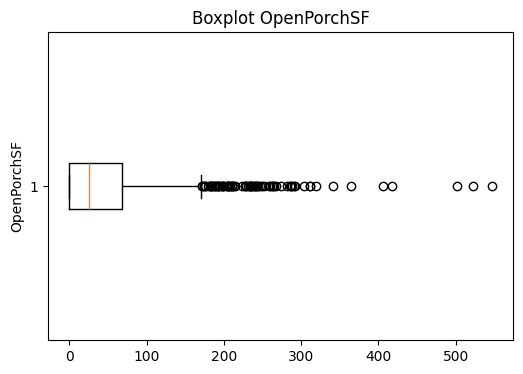

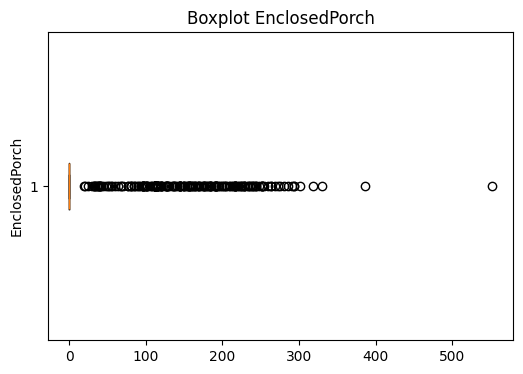

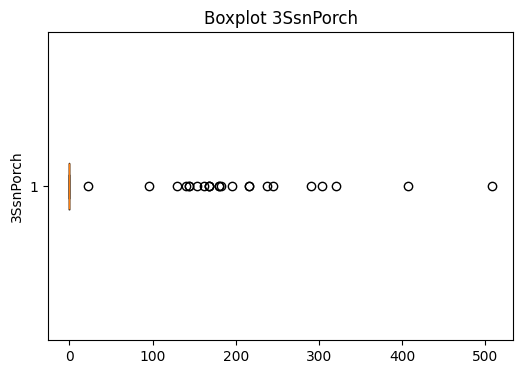

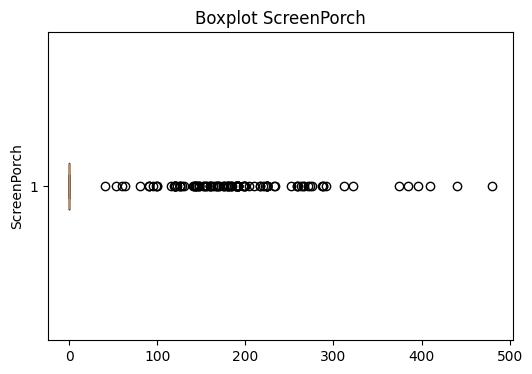

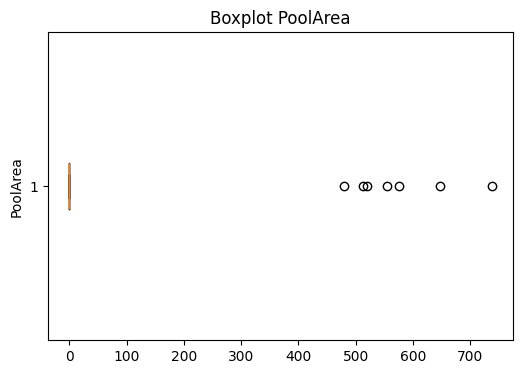

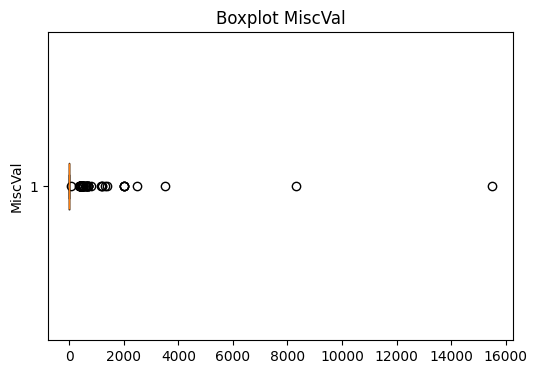

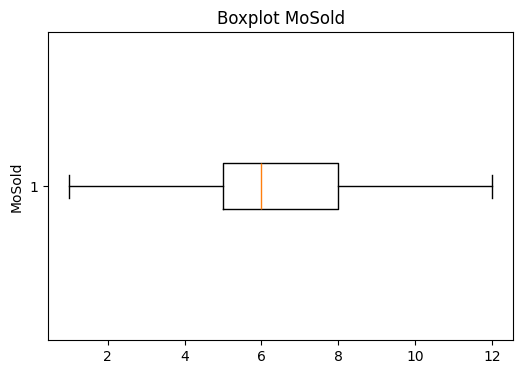

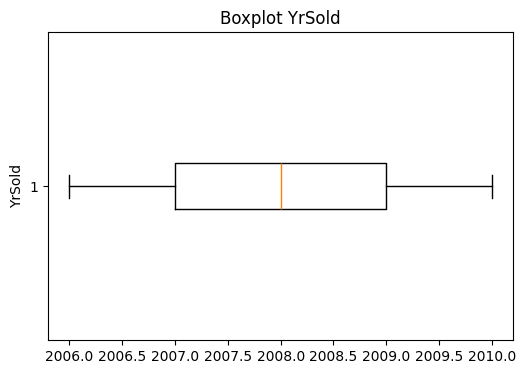

In [244]:
_df = df.drop(columns=['Id','SalePrice'])
cl= _df.select_dtypes(include=[np.number]).columns.tolist()
for col in cl:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col],vert=False)
    plt.title(f'Boxplot {col}')
    plt.ylabel(col)
    plt.show()

In [245]:
outlier_summary = []

for col in cl:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    if IQR == 0:
        outlier_count = 0
        lower_bound = Q1
        upper_bound = Q3
    else:
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_count = (
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
        ).sum()

    outlier_summary.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count
    })

outlier_summary = pd.DataFrame(outlier_summary)

print(outlier_summary.sort_values(
    'Outlier Count',
    ascending=False
))

          Feature       Q1        Q3      IQR  Lower Bound  Upper Bound  \
4     OverallCond     5.00      6.00     1.00        3.500        7.500   
0      MSSubClass    20.00     70.00    50.00      -55.000      145.000   
7      MasVnrArea     0.00    164.25   164.25     -246.375      410.625   
1     LotFrontage    60.00     80.00    20.00       30.000      110.000   
28    OpenPorchSF     0.00     68.00    68.00     -102.000      170.000   
2         LotArea  7553.50  11601.50  4048.00     1481.500    17673.500   
11    TotalBsmtSF   795.75   1298.25   502.50       42.000     2052.000   
20   BedroomAbvGr     2.00      3.00     1.00        0.500        4.500   
27     WoodDeckSF     0.00    168.00   168.00     -252.000      420.000   
15      GrLivArea  1129.50   1776.75   647.25      158.625     2747.625   
22   TotRmsAbvGrd     5.00      7.00     2.00        2.000       10.000   
10      BsmtUnfSF   223.00    808.00   585.00     -654.500     1685.500   
26     GarageArea   334.5

In [246]:
for col in cl:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    if IQR == 0:
        continue

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

Outlier dideteksi menggunakan boxplot pada atribut numerik kontinu. Hasil deteksi menunjukkan beberapa atribut memiliki observasi ekstrem, terutama `MasVnrArea`, `LotFrontage`, `OpenPorchSF`, `LotArea`, dan `TotalBsmtSF`. Namun, nilai ekstrem tidak langsung dianggap sebagai kesalahan karena pada dataset perumahan nilai tersebut dapat merepresentasikan properti dengan ukuran atau fasilitas yang memang lebih besar daripada mayoritas data. Selain itu, beberapa atribut memiliki distribusi yang sangat didominasi nilai nol sehingga IQR dapat memberikan indikasi outlier yang menyesatkan. Oleh karena itu, observasi tidak dihapus. Outlier pada atribut kontinu dengan distribusi yang sesuai ditangani menggunakan IQR capping untuk membatasi pengaruh nilai ekstrem sekaligus mempertahankan seluruh 1.460 observasi.

# Transformasi Data

* Lakukan normalisasi/standarisasi atribut.
* Lakukan encoding atribut kategoris menggunakan one-hot encoding.


In [247]:
X = df.drop(columns=['SalePrice', 'Id'])
y = df['SalePrice']

numeric_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=['object']
).columns.tolist()

print('Numerical:', len(numeric_cols))
print('Categorical:', len(categorical_cols))

Numerical: 36
Categorical: 38


In [248]:
scaler = StandardScaler()

X_numeric_scaled = scaler.fit_transform(
    X[numeric_cols]
)

In [249]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_categorical_encoded = encoder.fit_transform(
    X[categorical_cols]
)

In [250]:
X_transformed = np.hstack([
    X_numeric_scaled,
    X_categorical_encoded
])

print('Shape setelah encoding + standardisasi:',
      X_transformed.shape)

Shape setelah encoding + standardisasi: (1460, 281)


# Reduksi Dimensi

In [251]:
corr_matrix = df[cl].corr()
corr_matrix


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
MSSubClass,1.000000,-0.413954,-0.403395,0.062802,-0.085384,0.055790,0.058578,0.034657,-0.076423,-0.069351,...,-0.085825,-0.009879,0.001883,-0.015453,-0.043803,-0.021757,0.012660,-0.011390,-0.003956,-0.021216
LotFrontage,-0.413954,1.000000,0.618181,0.247239,-0.051011,0.142534,0.078215,0.229923,0.169321,0.060814,...,0.361191,0.115304,0.152714,-0.012210,0.076030,0.057921,0.070456,0.009654,0.012280,0.004873
LotArea,-0.403395,0.618181,1.000000,0.221597,-0.026494,0.065765,0.054472,0.144086,0.215825,0.094716,...,0.344650,0.198311,0.162026,-0.006923,0.069183,0.107368,0.101145,0.056272,0.003855,-0.036831
OverallQual,0.062802,0.247239,0.221597,1.000000,-0.134096,0.575160,0.550829,0.414226,0.229728,-0.059602,...,0.568181,0.246423,0.358426,-0.114672,0.030356,0.064833,0.065313,-0.031597,0.069460,-0.027299
OverallCond,-0.085384,-0.051011,-0.026494,-0.134096,1.000000,-0.399685,0.038429,-0.150941,-0.045411,0.049485,...,-0.177911,-0.011283,-0.082415,0.082759,0.025509,0.059545,-0.000021,0.065523,-0.009981,0.046162
YearBuilt,0.055790,0.142534,0.065765,0.575160,-0.399685,1.000000,0.594909,0.346081,0.252815,-0.049563,...,0.487439,0.238377,0.262130,-0.386843,0.031331,-0.050805,0.004893,-0.034583,0.012885,-0.013292
YearRemodAdd,0.058578,0.078215,0.054472,0.550829,0.038429,0.594909,1.000000,0.185138,0.126339,-0.067759,...,0.377331,0.222702,0.280916,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743
MasVnrArea,0.034657,0.229923,0.144086,0.414226,-0.150941,0.346081,0.185138,1.000000,0.247185,-0.074082,...,0.384180,0.161904,0.172885,-0.120754,0.035578,0.058447,-0.000430,-0.032655,0.008498,0.002687
BsmtFinSF1,-0.076423,0.169321,0.215825,0.229728,-0.045411,0.252815,0.126339,0.247185,1.000000,-0.050337,...,0.278350,0.209159,0.088830,-0.104684,0.028826,0.067568,0.068572,0.004498,-0.004769,0.013968
BsmtFinSF2,-0.069351,0.060814,0.094716,-0.059602,0.049485,-0.049563,-0.067759,-0.074082,-0.050337,1.000000,...,-0.015596,0.070105,-0.017674,0.036543,-0.029993,0.088871,0.041709,0.004940,-0.015211,0.031706


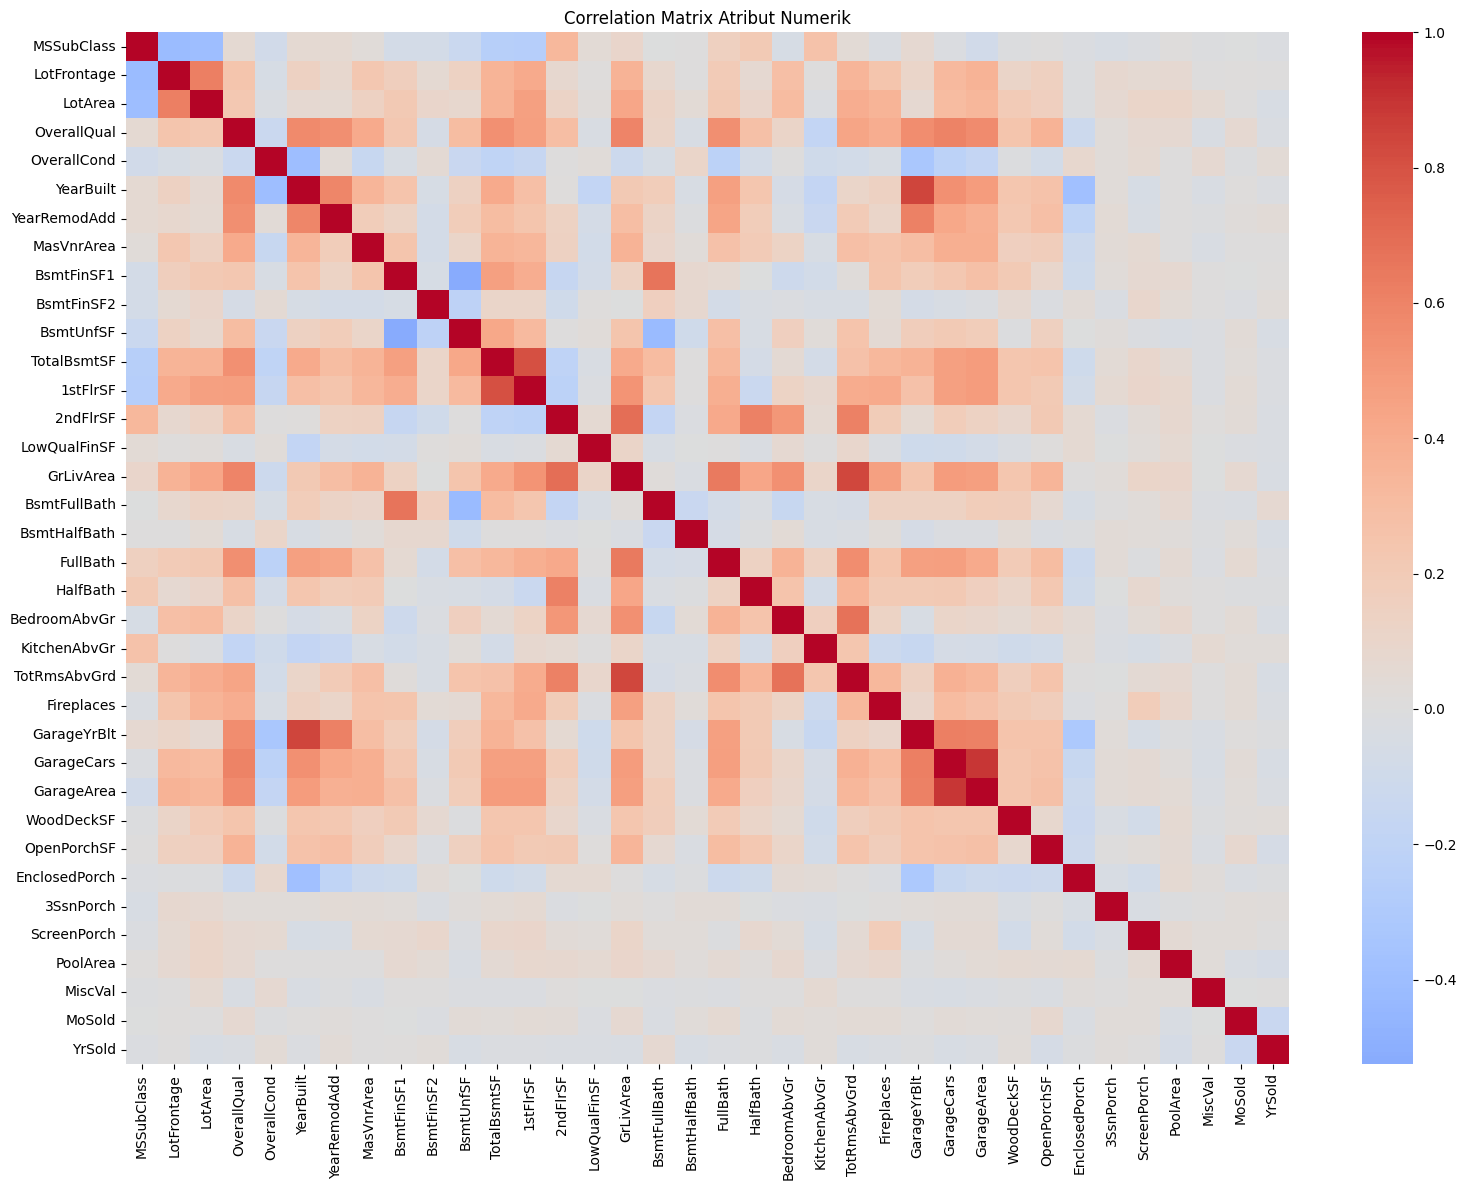

In [252]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix Atribut Numerik')
plt.tight_layout()
plt.show()

In [253]:
corr_abs = corr_matrix.abs()

upper = corr_abs.where(
    np.triu(
        np.ones(corr_abs.shape),
        k=1
    ).astype(bool)
)

high_corr = (upper.stack().sort_values(ascending=False))

print(high_corr[high_corr >= 0.50])

GarageCars    GarageArea      0.894560
YearBuilt     GarageYrBlt     0.845339
GrLivArea     TotRmsAbvGrd    0.835192
TotalBsmtSF   1stFlrSF        0.807158
2ndFlrSF      GrLivArea       0.691095
BedroomAbvGr  TotRmsAbvGrd    0.675435
BsmtFinSF1    BsmtFullBath    0.663118
GrLivArea     FullBath        0.641861
GarageYrBlt   GarageCars      0.623784
LotFrontage   LotArea         0.618181
GarageYrBlt   GarageArea      0.612188
2ndFlrSF      TotRmsAbvGrd    0.610949
              HalfBath        0.610165
YearRemodAdd  GarageYrBlt     0.607202
OverallQual   GarageCars      0.605169
              GrLivArea       0.597217
YearBuilt     YearRemodAdd    0.594909
OverallQual   YearBuilt       0.575160
              GarageArea      0.568181
              GarageYrBlt     0.557967
FullBath      TotRmsAbvGrd    0.556469
OverallQual   YearRemodAdd    0.550829
              FullBath        0.550501
GrLivArea     BedroomAbvGr    0.546937
YearBuilt     GarageCars      0.543050
OverallQual   TotalBsmtSF

In [254]:
high_corr_filtered = high_corr[high_corr >= 0.80]
to_drop = list(set([col2 for col1, col2 in high_corr_filtered.index]))
df= df.drop(columns=to_drop,axis=1)
print("Kolom yang di-drop:", to_drop)

Kolom yang di-drop: ['GarageArea', 'GarageYrBlt', '1stFlrSF', 'TotRmsAbvGrd']


In [255]:
X = df.drop(columns=['SalePrice', 'Id'])

numeric_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=['object']
).columns.tolist()

In [256]:
scaler = StandardScaler()
X_num = scaler.fit_transform(
    X[numeric_cols]
)
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)
X_cat = encoder.fit_transform(
    X[categorical_cols]
)
X_final = np.hstack([
    X_num,
    X_cat
])
print(X_final.shape)

(1460, 277)


In [257]:
pca = PCA(
    n_components=0.95,
    svd_solver='full'
)

X_pca = pca.fit_transform(X_final)

print('Jumlah komponen PCA:', pca.n_components_)
print('Explained variance:',
      pca.explained_variance_ratio_.sum())

Jumlah komponen PCA: 74
Explained variance: 0.9510359852935398


In [258]:
pca_columns = [
    f'PC{i+1}'
    for i in range(X_pca.shape[1])
]

df_pca = pd.DataFrame(
    X_pca,
    columns=pca_columns,
    index=df.index
)

df_pca['SalePrice'] = y.values
df_pca.insert(0, 'Id', df['Id'].values)

print(df_pca.shape)
print(df_pca.head())

(1460, 76)
   Id       PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0   1  2.117744  0.502830 -1.739533 -1.706147 -0.149409 -1.215595 -1.505273   
1   2 -0.070130 -1.775129  1.328580 -0.096883 -1.438771 -0.503944  0.798561   
2   3  2.850852  0.643230 -0.785389 -1.237905 -0.363852 -0.658737 -0.269174   
3   4 -1.095829  1.353223  1.460318 -0.416901  0.174736  2.546737 -1.007689   
4   5  4.982067  0.867655  0.721234 -1.241743  0.090454 -0.827366 -0.048869   

        PC8       PC9  ...      PC66      PC67      PC68      PC69      PC70  \
0 -1.013779 -0.252309  ... -0.099653 -0.090316 -0.175818  0.019898  0.195553   
1  2.431145 -0.348384  ... -0.186280  0.329550  0.104762 -0.039690  0.342016   
2 -0.180755 -0.683666  ...  0.012852 -0.017486 -0.280481  0.229373  0.133194   
3 -1.074085 -0.892324  ...  0.218251  0.300719 -1.139290  0.280231  0.049124   
4  0.345178 -1.305030  ...  0.156454 -0.124778  0.154228 -0.033196  0.012767   

       PC71      PC72      PC73  

In [259]:
# Dataset berseih sebelum Onehot Encoder dan PCA
df.to_csv('house_prices_cleaned.csv', index=False)

In [260]:
# Dataset PCA
df_pca.to_csv('house_prices_final_pca.csv', index=False)